# Notebook 17: Negative Dwell Time, or What a Weak Probe Reports

**Goal:** In 2024 Angulo, Steinberg and co-workers measured how long the atoms of a cold cloud stay excited because of a photon that is *transmitted*, and found a
negative time (arXiv:2409.03680). Build a closed model of that experiment, split the measured quantity into a division-event part and an indivisibility part, and ask
what an ISP can and cannot say about "time spent".

By the end of this notebook you will be able to:
- State and prove the identity $q = P_\text{seq} + \Delta/2$ that connects a weak value to Barandes's division events (the model's numerics reproduce it to machine precision, a consistency check of the code)
- Reproduce the negative excitation time and its equality with the group delay in a model of atoms in a one-way waveguide
- Say what the split does mean (a negative value witnesses indivisibility) and what it doesn't (the division-event part is not an "honest" time)
- Watch the negative time turn positive, then vanish, as the probe gets stronger
- Find the same effect in a second system: a reflected particle "spends negative time" behind a tunnelling barrier

---
> ### 📓 Annotated study copy
>
> Study copy of `17_negative_dwell_time.ipynb`. Same code and outputs, plus sections marked **📖 In depth**, **🔍 Reading the code** and **🔭 Looking ahead**.
>
> Written 2026-11-09 from `notes/negative-dwell-time-spike-2026-11-09.md`, prompted by four papers outside the Barandes series
> (`notes/additional-papers-isp-angles-2026-11-09.md`). The question: *a photon "spends negative time" as an atomic excitation. What does an indivisible stochastic process say about that?*
> Short answer: a negative reported time is a witness that the process did not divide at all of those times, and ISP has no non-negative "time spent" to offer instead.
>
> **Prior work.** The identity is Halliwell's (arXiv:1508.02271); the excitation-time prediction is Thompson et al.'s (arXiv:2310.00432); weak-value dwell times, and the negative time behind a
> barrier, go back to Steinberg (1995). What may be new is only the reading (see the 🔭 cell at the end).
>
> **Audit (2026-11-10).** An independent rerun with separate code confirmed the identity and every printed number. It found that the split depends on how the question is recorded, that the
> strong-probe limit is detuning rather than the Zeno effect, and that the model's line is not quite a dilute cloud's. This version says so.
---

### 📖 In depth: what Γ explains about negative dwell times, and what it doesn't

**What Γ explains**
- **Why there is no positive answer.** A positive "time spent excited, given transmission" needs joint probabilities across times; an ISP has them only at division events (section 4).
- **Where the negative number comes from.** It is half the indivisibility defect showing through the weak probe (sections 2–3).
- **What happens when you look harder.** A stronger probe disturbs more, and the number turns positive and then vanishes (section 5). In this model the disturbance is a detuning of the atoms, not a record at each moment.

**What Γ does not explain**
- **The size of the effect.** The value equals the group delay, a derivative of a *phase* of the transmitted light. Γ in the frequency basis is diagonal and blind to it.
- **Why the probe reports Re of a weak value.** That is pointer physics (a linear response), computed from amplitudes.
- **A "true" dwell time.** The split does not supply one: the division-event part is invasive and depends on the grain of the record (section 4).

**Net.** ISP turns the paradox into a diagnosis: a negative time is a measured violation of divisibility, not a fact about how long anything stayed anywhere.

<!-- expansion:17:before-you-start -->
### 🧭 Before you start

**What this notebook is for.** A 2024 experiment asked how long atoms stay excited because of a photon that passes through them, and got a
negative number. This notebook builds a closed model of that experiment and asks what Barandes's picture says about it. In that picture a system always
occupies one definite configuration and moves between configurations with *indivisible* probabilities Γ. The answer: the number the probe
reports is a recorded probability plus half of Barandes's indivisibility defect, and a negative report is a witness that the process did not divide.

**Prerequisites.**
- Notebook 05: the indivisibility defect as an interference term.
- Notebook 06: division events (records) and what they do to Γ.
- Notebook 10: the level+band model and its defect Δ for "decayed or not"; this notebook's model is the same idea with two kinds of band.
- Notebook 11: dense records and the Zeno effect, a useful contrast for section 5's strong probe.
- No prior knowledge of weak values or group delay; the 🧮 cells derive what is needed.

**How to run it.** From the `notebooks/` folder, *Kernel > Restart & Run All*, or step through with Shift+Enter. The first code cell adds
the folder one level up to `sys.path` and imports from `isp/dwell.py`, so `isp/` must sit next to `notebooks/`. Only numpy and matplotlib
are needed. The whole notebook takes about four minutes; most of it is section 3's runs, section 4's split check and section 5's probe curve.


<!-- expansion:17:glossary -->
### 📘 Glossary

- **Configuration.** Here: atom $j$ excited; the photon in forward (waveguide) mode $k$; or the photon in atom $j$'s private loss mode.
- **Γ.** $\Gamma_{ij}(t\leftarrow 0)$ = probability of being in $i$ at $t$, given $j$ at 0. Here $\Gamma = |U|^2$ with $U = e^{-iHt}$.
- **τ_sp.** The atom's lifetime, 26 ns for the experiment's rubidium; the unit of time in sections 1–5.
- **Optical depth (OD).** $-\ln$ of the resonant intensity transmission. OD 2.2 lets about 11% of resonant light through; OD 4 about 2%.
- **Post-selection $f$.** Keeping only the runs with a given final outcome, here "the photon was transmitted".
- **Weak value.** What a probe too gentle to disturb the system reports, averaged over the post-selected runs. It can lie outside the range of the measured quantity, including negative.
- **Quasiprobability $q$ (Margenau–Hill, Kirkwood–Dirac).** The weak value times $P(f)$. It adds up like a probability but can be negative.
- **$P_\text{seq}$.** The joint probability of "in at $t$, then $f$" when the in/out question is actually recorded at $t$ (a division event of that variable).
- **Indivisibility defect $\Delta_f$.** How much that recording changes $P(f)$: $P(f) - \sum_b P_\text{seq}(b, f)$.
- **Excitation time $\tau_T$.** $\int q\,dt / P(f)$: the probe's report of how long the atoms were excited, per transmitted photon. **$\tau_0$** is the same without post-selection.
- **Group delay $\tau_g$.** $d\varphi/d\omega$, the derivative of the transmitted light's phase with respect to frequency: how late the peak of a smooth pulse comes out.
- **Dwell time.** Time spent in a region. The tunnelling version (section 6) asks for time spent in a set of sites.
- **Pointer.** A model probe: a particle whose position shifts in proportion to the measured quantity. Its resolution $\sigma_x$ sets how weak it is.


In [1]:
#import a bunch of python libraries
import sys
import os
sys.path.insert(0, os.path.abspath('..'))

%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
from isp.dwell import ChiralChain, TunnelChain, decompose, pointer_shift, pointer_shift_discrete

### 📖 In depth: the idea in plain words

- **The experiment.** Shine single photons at a cloud of atoms. Some get through. Use a second, very gentle laser to estimate how long the atoms were excited by the photons that got through. The
  answer comes out negative.
- **The trick.** "How long was the atom excited, given that the photon got through later?" mixes two times: now (excited?) and later (through?). In ordinary probability that is fine. In an
  indivisible process there is no table of probabilities for "excited now *and* through later" unless the process is checked in between, and checking changes the answer.
- **What the gentle laser measures.** A quantity that would be that joint probability if it existed, plus half of the amount by which checking would change the final result. The second piece
  can be negative and big.
- **For a search engineer.** Ask "how long did users who eventually clicked spend on the second result?" from logs that only record the final click and a faint, averaged signal of attention. If
  attention and clicking interfere (looking changes whether you click), the faint signal can average to a negative "attention time" for clickers. The number is real data, but it is not a time.

## 1. The Experiment as a Closed Process

The experiment sends weak resonant pulses through a cloud of rubidium atoms (lifetime $\tau_\text{sp} = 26$ ns) and keeps only the runs in which a photon comes out the far side. A second, far-detuned beam
picks up a tiny phase proportional to the number of excited atoms; averaged over the post-selected runs, its time integral is the atoms' excitation time $\tau_T$ caused by a transmitted photon.
They report $\tau_T/\tau_0$ from $+0.54 \pm 0.28$ for 10 ns pulses (OD about 4) to $-0.82 \pm 0.31$ for 36 ns pulses (OD about 3, the highest they could use at that pulse length), where $\tau_0$
is the excitation time without post-selection. They define $\tau_0 = \int\langle \hat N_e\rangle\,dt$, measure it with the same probe (without post-selection), and note that semiclassically it equals the scattering
probability times $\tau_\text{sp}$. In a dilute cloud the two agree. In the model below they do not: light re-emitted into the beam ($\Gamma_\text{1d}$) is not scattered, so
$\int\langle \hat N_e\rangle\,dt = P_\text{scatt}\,\tau_\text{sp}/0.9$. The notebook uses the defining integral; dividing by $P_\text{scatt}\,\tau_\text{sp}$ instead multiplies every ratio by $1/0.9$ (section 3 prints both).
The experiment integrates both traces only inside a window cut where the tails of the theory curve reach 30% of its peak; the model integrates over the whole run.

The model is the single-excitation sector of $N$ two-level atoms in a one-way (chiral) waveguide. Its configurations are: atom $j$ is excited; the photon is in forward mode $k$; or the photon is in
atom $j$'s private loss mode (light scattered out of the beam). It is notebook 10's level+band model with two kinds of band, and it is closed, so $\Gamma = |U|^2$. Units: $\tau_\text{sp} = 1$,
with a coupling into the beam $\Gamma_\text{1d} = 0.1$ and out of it $\Gamma_\text{loss} = 0.9$. Five atoms give optical depth 2.2 and nine give 4.0, the two depths of the experiment.

**How close to the real cloud.** Each model atom has optical depth 0.45, so a few atoms each block a lot of light. A real cloud is many atoms each blocking very little, and its line shape
(the "dilute" line that Thompson et al. treat) is slightly different: on resonance the model's group delay at OD 2.23 is $-2.5\,\tau_\text{sp}$, the dilute line's $-2.23\,\tau_\text{sp}$. Broadband
pulses barely notice; for narrowband pulses the model's ratios differ from the dilute-line theory by up to about 0.2. Read the comparisons below as semi-quantitative.

<!-- expansion:17:books-angulo -->
### 📚 From the paper: what Angulo et al. measured and claim

Angulo, Thompson, Nixon, Jiao, Wiseman & Steinberg, "Experimental evidence that a photon can spend a negative amount of time in an atom cloud" (arXiv:2409.03680; PRL 136, 153601 (2026)).
Quotes are from the arXiv v1 PDF, with reference numbers omitted.

- **The question.** "Should the group delay experienced by photons be attributed to the time they spend as atomic excitations? However reasonable this
  connection may seem, it appears problematic when the frequency of the light is close to the atomic resonance, as the group delay becomes negative in this regime."
- **The probe.** "we use the cross-Kerr effect to probe the degree of atomic excitation caused by a resonant transmitted photon, by measuring the phase shift on a separate beam
  that is weak and off-resonant."
- **What is measured, as a weak value.** "the atomic excitation time caused by a transmitted photon, τ_T, is given by the time integral of the real part of the weak value of N̂_e,
  with the initial state specified by the preparation of the input photon and the final state (post-selection) being that of the photon having traversed the medium without scattering."
- **Their reading.** "These results suggest that negative values taken by times such as the group delay have more physical significance than has generally been appreciated."

This notebook's section 2 splits exactly that time integral, and section 4 offers a different reading from the last quote: physically significant, yes,
but as a measured violation of divisibility rather than a time anything spends anywhere.


N = 5: 1405 configurations, optical depth 2.23, recurrence time 63 τ_sp
N = 9: 2209 configurations, optical depth 4.02, recurrence time 63 τ_sp


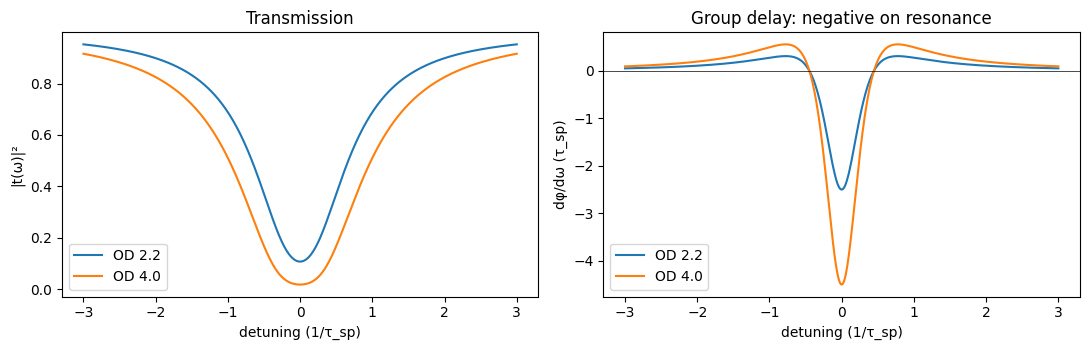

In [2]:
chains = {N: ChiralChain(N) for N in (5, 9)}
for N, ch in chains.items():
    print(f"N = {N}: {ch.D} configurations, optical depth {ch.OD:.2f}, recurrence time {ch.recurrence_time:.0f} τ_sp")

w = np.linspace(-3, 3, 601)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for N, ch in chains.items():
    t = ch.transmission(w)
    ax[0].plot(w, np.abs(t) ** 2, label=f'OD {ch.OD:.1f}')
    ax[1].plot(w, np.gradient(np.unwrap(np.angle(t)), w), label=f'OD {ch.OD:.1f}')
ax[0].set_xlabel('detuning (1/τ_sp)'); ax[0].set_ylabel('|t(ω)|²'); ax[0].set_title('Transmission'); ax[0].legend()
ax[1].set_xlabel('detuning (1/τ_sp)'); ax[1].set_ylabel('dφ/dω (τ_sp)'); ax[1].set_title('Group delay: negative on resonance')
ax[1].axhline(0, color='k', lw=0.5); ax[1].legend(); plt.tight_layout(); plt.show()

<!-- expansion:17:recap-1 -->
### 📝 Recap: section 1

- A closed model: $N$ atoms, a forward band, and one loss band per atom; $\Gamma = |U|^2$ in that configuration basis.
- Five atoms give OD 2.2 and nine give OD 4.0, the experiment's two depths.
- The left plot is a transmission dip on resonance. The right plot is the group delay of continuous light: negative near resonance, positive in the wings
  (the 🧮 cell in section 3 derives both).
- The post-selection is fixed here: the photon ends in the forward band.
- Each model atom is optically thick (OD 0.45), so the line is close to, but not exactly, a dilute cloud's. Comparisons with the experiment are semi-quantitative.


## 2. The Identity

Take a yes/no question about an intermediate time $t$ ("is an atom excited?", projector $\Pi_\text{in}$, complement $\Pi_\text{out}$) and a post-selection $f$ at the end ("the photon was transmitted").
The weak probe reports the real part of the weak value; multiplied by $P(f)$ it is the Margenau–Hill quasiprobability

$$q(\text{in}, f; t) = \mathrm{Re}\,\langle\psi|\Pi_\text{in}(t)\,\Pi_f(T)|\psi\rangle .$$

Insert $\Pi_\text{in}(t) + \Pi_\text{out}(t) = 1$ between $\Pi_f(T)$ and $|\psi\rangle$ and it splits into two pieces:

$$q(\text{in}, f; t) = P_\text{seq}(\text{in}, f; t) + \tfrac12\,\Delta_f(t), \qquad \Delta_f = P(f) - P_\text{seq}(\text{in}, f) - P_\text{seq}(\text{out}, f).$$

- $P_\text{seq}$ is the probability of "in at $t$, then $f$" when the in/out question is actually *recorded* at $t$: in Barandes's terms, with a division event of that variable at $t$. It is never negative.
- $\Delta_f$ is how much that division event changes the final probability of $f$: the indivisibility defect of notebooks 05 and 10, for this coarse variable. It is $2\,\mathrm{Re}\,D$ in the
  language of decoherent histories, and the no-signalling-in-time violation of the Leggett–Garg literature. Each of the two answers gets exactly half of it.
- The sum $q$ does not depend on how the question is recorded, but the two pieces do: record *which* atom is excited instead of *whether* one is, and the split changes (section 4).

The proof is two lines of algebra. After the insertion, $\Pi_\text{in}$ paired with $\Pi_\text{in}$ gives $P_\text{seq}(\text{in}, f)$ and the cross term is $\mathrm{Re}\,\langle\psi|\Pi_\text{in}(t)\Pi_f(T)\Pi_\text{out}(t)|\psi\rangle$;
expanding $P(f) = \langle\psi|\Pi_f(T)|\psi\rangle$ the same way shows that this cross term is $\Delta_f/2$. The code below therefore does not test the identity; its residual only checks that the model's time evolution is computed consistently.

The identity is Halliwell's (arXiv:1508.02271, PRA 93, 022123 (2016), eqs. (2.1), (2.4)–(2.5)). That paper prints $q = p + 2\,\mathrm{Re}\,D$, a factor its own definition of $D$ does not
support; the corrected form $q = p + \mathrm{Re}\,D$ is in Halliwell et al., PRA 99, 012124 (2019), eq. (2.3). The excitation time is the identity's time integral, $\tau_T = \int q\,dt / P(f)$.

<!-- expansion:17:derive-qubit -->
### 🧮 Worked derivation: a negative weak value in one qubit

The identity of this section needs nothing but a two-state system. Let the state at $t$ be $|\psi_t\rangle = (|\text{in}\rangle + |\text{out}\rangle)/\sqrt2$, and let nothing happen
between $t$ and $T$, so $A = \Pi_f = |\phi\rangle\langle\phi|$ with $|\phi\rangle = \cos\theta\,|\text{in}\rangle - \sin\theta\,|\text{out}\rangle$. Then

$$q = \mathrm{Re}\,\langle\psi_t|\Pi_\text{in}|\phi\rangle\langle\phi|\psi_t\rangle = \tfrac12\cos\theta(\cos\theta - \sin\theta),\qquad P(f) = \tfrac12(\cos\theta - \sin\theta)^2 .$$

Recorded at $t$: $P_\text{seq}(\text{in}, f) = \tfrac12\cos^2\theta$ and $P_\text{seq}(\text{out}, f) = \tfrac12\sin^2\theta$, which add to $\tfrac12$. So $\Delta_f = P(f) - \tfrac12 = -\sin\theta\cos\theta$, and indeed
$q = P_\text{seq}(\text{in}, f) + \Delta_f/2$.

Take $\theta = 60°$:
- $P_\text{seq}(\text{in}, f) = 0.125$ and $\Delta_f/2 = -0.217$, so $q = -0.092$.
- $P(f) = 0.067$, so the weak value of "in" is $q/P(f) = -1.37$: outside $[0, 1]$.

The recipe for a big anomalous value is visible here: a post-selection nearly orthogonal to the state makes $P(f)$ small, while the defect stays of order one.
In the experiment the "rare" outcome is a resonant photon surviving the cloud.


36 ns pulse, OD 2.23: largest |q − P_seq − Δ/2| over 400 times = 5.7e-16
P(transmitted) = 0.227;  τ_T = -0.598 = τ_seq +0.994 + τ_defect -1.592   (units τ_sp)


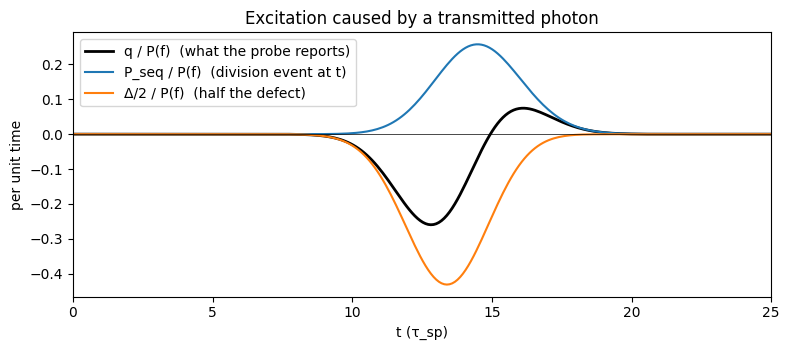

In [3]:
ch = chains[5]
d = ch.run(36 / 26)
print(f"36 ns pulse, OD {ch.OD:.2f}: largest |q − P_seq − Δ/2| over {len(d['t'])} times = {d['identity_err']:.1e}")
print(f"P(transmitted) = {d['P_f']:.3f};  τ_T = {d['tau']:+.3f} = τ_seq {d['tau_seq']:+.3f} + τ_defect {d['tau_defect']:+.3f}   (units τ_sp)")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(d['t'], d['q'] / d['P_f'], 'k', lw=2, label='q / P(f)  (what the probe reports)')
ax.plot(d['t'], d['seq'] / d['P_f'], label='P_seq / P(f)  (division event at t)')
ax.plot(d['t'], d['defect_half'] / d['P_f'], label='Δ/2 / P(f)  (half the defect)')
ax.axhline(0, color='k', lw=0.5); ax.set_xlim(0, 25)
ax.set_xlabel('t (τ_sp)'); ax.set_ylabel('per unit time'); ax.set_title('Excitation caused by a transmitted photon'); ax.legend()
plt.tight_layout(); plt.show()

### 📖 In depth: the two-line proof

Write $|\psi_t\rangle$ for the state at $t$ and $A = U(T,t)^\dagger \Pi_f U(T,t)$. Then $q = \mathrm{Re}\,\langle\psi_t|\Pi_\text{in} A|\psi_t\rangle$. Insert $1 = \Pi_\text{in} + \Pi_\text{out}$ to the right of $A$:

$$q = \langle\psi_t|\Pi_\text{in} A \Pi_\text{in}|\psi_t\rangle + \mathrm{Re}\,\langle\psi_t|\Pi_\text{in} A \Pi_\text{out}|\psi_t\rangle .$$

The first term is $P_\text{seq}(\text{in}, f)$. For the final probability, $P(f) = \langle\psi_t|A|\psi_t\rangle$, expand both sides: $P(f) = P_\text{seq}(\text{in}) + P_\text{seq}(\text{out}) + 2\,\mathrm{Re}\,\langle\psi_t|\Pi_\text{in}A\Pi_\text{out}|\psi_t\rangle$.
So the cross term is $\Delta_f/2$. With more than two answers the cross terms no longer split evenly, so the clean "half each" is special to yes/no questions.

<!-- expansion:17:recap-2 -->
### 📝 Recap: section 2

- What the weak probe reports, times $P(f)$, is $q = P_\text{seq} + \Delta_f/2$: the recorded joint probability plus half the indivisibility defect. Exact, for any yes/no question.
- The proof is pure algebra; the model's numerics reproduce it to about $10^{-15}$ at every time (a consistency check of the code); the 36 ns pulse gives $\tau_T < 0$ with $\tau_\text{seq} > 0$ and a larger negative defect term.
- The sum is fixed, but the two pieces depend on how the question is recorded (section 4).
- The identity is not new (Halliwell, arXiv:1508.02271). What this notebook adds is reading $\Delta_f$ as Barandes's defect and following it through the experiment.


## 3. The Excitation Time Is the Group Delay

Thompson et al. (arXiv:2310.00432) predicted that $\tau_T$ equals the group delay of the transmitted light, even when that is negative. The integrated quasiprobability is
$\int q\,dt = -\mathrm{Im}\,\langle\text{out}_f|\partial_\eta\,\text{out}_f\rangle$: the derivative of the transmitted light's phase with respect to a shift $\eta$ of the atomic levels, and shifting the atoms is the same as shifting the light's frequency. Below, the four pulse lengths of the experiment and a longer
one, at both optical depths. The like-for-like comparison is with the group delay of the model's own transmitted light. The ideal continuum formula is printed too: it differs by up to about 17% at
OD 4, because the finite loss bands reshape the atomic line slightly (doubling their width moves the model toward the continuum). That matters most where $\tau_T$ is near zero: at 27 ns, OD 4
the two even have opposite signs, so that point's sign is not a prediction. One extra point, seven atoms (OD 3.1) at 36 ns, matches the depth of the experiment's narrowband point.

<!-- expansion:17:derive-group-delay -->
### 🧮 Worked derivation: why the group delay is negative on resonance

One atom in this model passes light with amplitude

$$t_1(\Delta) = \frac{\Delta + i a}{\Delta + i b},\qquad a = \tfrac12(\Gamma_\text{loss} - \Gamma_\text{1d}) = 0.4,\quad b = \tfrac12(\Gamma_\text{loss} + \Gamma_\text{1d}) = 0.5,$$

where $\Delta$ is the detuning from resonance (this is `ChiralChain.t1`). On resonance $|t_1|^2 = a^2/b^2 = 0.64$, so each atom adds $2\ln(b/a) = 0.446$ to the optical depth: five atoms give 2.23.
The phase is $\varphi_1 = \arctan(a/\Delta) - \arctan(b/\Delta)$, and its derivative is

$$\tau_{g,1}(\Delta) = \frac{d\varphi_1}{d\Delta} = \frac{b}{\Delta^2 + b^2} - \frac{a}{\Delta^2 + a^2}.$$

- **On resonance:** $\tau_{g,1}(0) = 1/b - 1/a = -0.5\,\tau_\text{sp}$ per atom, so $-2.5\,\tau_\text{sp}$ for five atoms. Negative.
- **Far off resonance:** $\tau_{g,1} \approx (b - a)/\Delta^2 > 0$. Positive: ordinary slow light.
- **Sign change:** at $|\Delta| = \sqrt{ab} \approx 0.45/\tau_\text{sp}$.

A pulse averages $\tau_g$ over its spectrum, weighted by what gets through. Most of a long (narrowband) pulse's spectrum lies inside $|\Delta| < 0.45$ (the 36 ns pulse's spectral rms width is 0.36),
so it sees mostly the negative delay. A short (broadband) pulse
spreads past it, and its resonant part is absorbed most, so the positive wings win. That is the sign pattern of section 3's table and of the experiment's Fig. 3.


OD 2.23


    10 ns: τ_T = +0.082  group delay (model's light) = +0.077  (continuum formula +0.085)  τ_T/τ_0 = +0.169  (÷ P_scatt τ_sp: +0.188)   [τ_seq +0.233, τ_defect -0.151]  identity err 8e-16


    18 ns: τ_T = -0.036  group delay (model's light) = -0.040  (continuum formula -0.023)  τ_T/τ_0 = -0.054  (÷ P_scatt τ_sp: -0.060)   [τ_seq +0.463, τ_defect -0.500]  identity err 6e-16


    27 ns: τ_T = -0.291  group delay (model's light) = -0.288  (continuum formula -0.262)  τ_T/τ_0 = -0.367  (÷ P_scatt τ_sp: -0.408)   [τ_seq +0.735, τ_defect -1.026]  identity err 6e-16


    36 ns: τ_T = -0.598  group delay (model's light) = -0.583  (continuum formula -0.558)  τ_T/τ_0 = -0.696  (÷ P_scatt τ_sp: -0.774)   [τ_seq +0.994, τ_defect -1.592]  identity err 6e-16


    52 ns: τ_T = -1.113  group delay (model's light) = -1.071  (continuum formula -1.068)  τ_T/τ_0 = -1.211  (÷ P_scatt τ_sp: -1.346)   [τ_seq +1.373, τ_defect -2.486]  identity err 6e-16
OD 4.02


... (2 outputs left out)

    27 ns: τ_T = -0.021  group delay (model's light) = -0.036  (continuum formula +0.015)  τ_T/τ_0 = -0.022  (÷ P_scatt τ_sp: -0.025)   [τ_seq +1.791, τ_defect -1.813]  identity err 5e-16


    36 ns: τ_T = -0.456  group delay (model's light) = -0.461  (continuum formula -0.390)  τ_T/τ_0 = -0.449  (÷ P_scatt τ_sp: -0.499)   [τ_seq +2.850, τ_defect -3.306]  identity err 4e-16


    52 ns: τ_T = -1.407  group delay (model's light) = -1.372  (continuum formula -1.306)  τ_T/τ_0 = -1.332  (÷ P_scatt τ_sp: -1.480)   [τ_seq +4.947, τ_defect -6.354]  identity err 3e-16


OD 3.12, 36 ns: τ_T/τ_0 = -0.603  (÷ P_scatt τ_sp: -0.670)   (Angulo et al.: −0.82 ± 0.31 at OD ≈ 3)
P_scatt τ_sp / τ_0 over the ten runs above: 0.9000 to 0.9000  (Γ_loss τ_sp = 0.9)


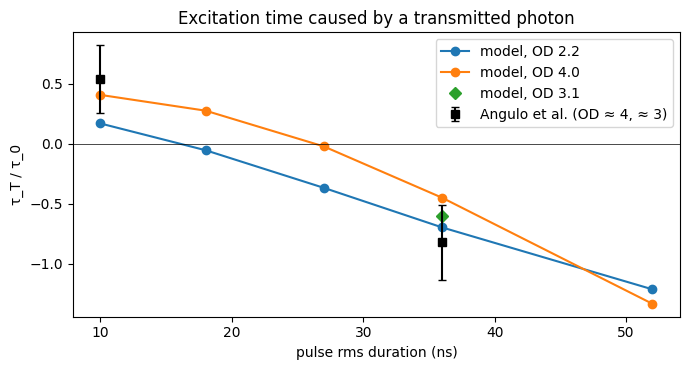

In [4]:
durations = [10 / 26, 18 / 26, 27 / 26, 36 / 26, 2.0]
results = {}
for N, ch in chains.items():
    print(f"OD {ch.OD:.2f}")
    for st in durations:
        r = ch.run(st, nt=300)
        tau0 = r['dwell']                  # τ_0 = ∫<N_e> dt, the paper's definition
        tau0_scatt = 1 - r['P_f']          # P_scatt × τ_sp (τ_sp = 1); equals 0.9 τ_0 in this model
        results[(N, st)] = (r, tau0)
        print(f"  {st*26:4.0f} ns: τ_T = {r['tau']:+.3f}  group delay (model's light) = {r['tau_g_model']:+.3f}  (continuum formula {r['tau_g']:+.3f})  τ_T/τ_0 = {r['tau']/tau0:+.3f}"
              f"  (÷ P_scatt τ_sp: {r['tau']/tau0_scatt:+.3f})   [τ_seq {r['tau_seq']:+.3f}, τ_defect {r['tau_defect']:+.3f}]  identity err {r['identity_err']:.0e}")
ch7 = ChiralChain(7)
r7 = ch7.run(36 / 26, nt=300)
print(f"OD {ch7.OD:.2f}, 36 ns: τ_T/τ_0 = {r7['tau']/r7['dwell']:+.3f}  (÷ P_scatt τ_sp: {r7['tau']/(1 - r7['P_f']):+.3f})   (Angulo et al.: −0.82 ± 0.31 at OD ≈ 3)")
print(f"P_scatt τ_sp / τ_0 over the ten runs above: {min((1 - r['P_f']) / t0 for r, t0 in results.values()):.4f} to {max((1 - r['P_f']) / t0 for r, t0 in results.values()):.4f}  (Γ_loss τ_sp = 0.9)")

fig, ax = plt.subplots(figsize=(7, 3.8))
for N, ch in chains.items():
    ax.plot([s * 26 for s in durations], [results[(N, s)][0]['tau'] / results[(N, s)][1] for s in durations], 'o-',
            label=f'model, OD {ch.OD:.1f}')
ax.plot([36], [r7['tau'] / r7['dwell']], 'D', color='C2', label=f'model, OD {ch7.OD:.1f}')
ax.errorbar([10, 36], [0.54, -0.82], yerr=[0.28, 0.31], fmt='ks', capsize=3, label='Angulo et al. (OD ≈ 4, ≈ 3)')
ax.axhline(0, color='k', lw=0.5); ax.set_xlabel('pulse rms duration (ns)'); ax.set_ylabel('τ_T / τ_0')
ax.set_title('Excitation time caused by a transmitted photon'); ax.legend()
plt.tight_layout(); plt.show()

### 🔍 Reading the code: why τ_T equals the group delay

Shift every atom's energy by $\eta$. Then $\partial_\eta U(T) = -i\int_0^T U(T,t)\Pi_\text{in}U(t)\,dt$, so $\int q\,dt = -\mathrm{Im}\,\langle\text{out}_f|\partial_\eta\,\text{out}_f\rangle$, where $|\text{out}_f\rangle$ is the
transmitted part of the final state. Each transmitted mode carries $t(\omega-\eta)$, so the derivative becomes $\sum_k |c_k|^2|t_k|^2\,\varphi'(\omega_k)$: the group delay averaged over the transmitted
spectrum. `run` evaluates that sum with $t(\omega_k)$ read off the model's own output modes (`tau_g_model`); `group_delay_pulse` uses the ideal continuum $t(\omega)$, which differs because the
discrete, finite bands (spacing 0.1, width 40 and 20) shift and reshape the line. `pointer_shift` uses the same
derivative trick inside an average over pointer momenta.

<!-- expansion:17:recap-3 -->
### 📝 Recap: section 3

- $\tau_T$ equals the pulse-averaged group delay of the transmitted light, because shifting the atoms is the same as shifting the light's frequency.
- In this model the agreement with the model's own transmitted light is within about 0.04 $\tau_\text{sp}$ in all ten cases; the ideal continuum formula is close but not exact, and at 27 ns, OD 4 it has the other sign.
- Broadband pulses give $\tau_T > 0$, narrowband ones $\tau_T < 0$. The 10 ns, OD 4 value is $+0.41$, against Thompson et al.'s $0.45$ and the measured $0.54 \pm 0.28$. At OD 3.1 and 36 ns the model
  gives $-0.60$, against the measured $-0.82 \pm 0.31$. Both agree within the error bars, but the model's choices move narrowband values by up to about 0.2, so this is a trend, not a fit.
- These ratios use the paper's definition $\tau_0 = \int\langle\hat N_e\rangle\,dt$. The paper's semiclassical shortcut, scattering probability times $\tau_\text{sp}$, is $0.9\,\tau_0$ in this model (the
  light re-emitted into the beam is not scattered), and with it the same two points read $+0.45$ and $-0.67$. The experiment obtains $\tau_0$ from the integral (its probe trace without post-selection), so the notebook uses that; in a dilute cloud the two agree.
- The size of the effect is a phase derivative, which Γ in the frequency basis cannot see. Γ explains the sign structure (section 4), not the magnitude.


## 4. What the Split Means, and What It Doesn't

Three readings are tempting, and only one survives.

**Tempting but wrong: "$\tau_\text{seq}$ is the honest time and the defect is a correction."** $\tau_\text{seq}$ is what you would get by *checking* at each time whether the particle is inside. Checking disturbs.
A tunnelling particle shows how badly: projecting it into the barrier gives it the large momenta needed to cross, so when transmission is rare $\tau_\text{seq}$ can be hundreds of times the
time the probe reports, with a defect of nearly the same size and opposite sign.

**Also wrong: "the split is a fixed fact about the experiment."** The two pieces depend on details that leave $\tau_T$ alone. Spacing the atoms further apart changes nothing about the light
that comes out (it changes only phases inside the guide), yet $\tau_\text{seq}$ falls from about $+1.0$ to $+0.5$. Recording *which* atom is excited, instead of *whether* one is, changes it again.
At other settings (nine atoms, a 10 ns pulse, spacing 0.5 or 1.0) the defect part even changes sign. The second code cell below shows all of this.

**What survives: a negative value witnesses indivisibility.** $P_\text{seq} \ge 0$ at every time. So if the probe reports a negative time, the in/out variable cannot have had a division event
at every probed time; at the times where $q < 0$, certainly none. No account in which the process divides at all those times, Markov or not, gives a negative number. In an ISP the atoms are excited or not at every
moment, but Γ gives no joint probability for "excited at $t$ and transmitted at $T$" without a division event at $t$, so "how long was the atom excited, given that the photon came out" has no
non-negative answer to report. What the experiment records is the final configuration of the probe's pointer and the photon; the pointer's average, given transmission, is a single-time quantity, and it is negative. The argument works for any record, coarse or fine, because every $P_\text{seq}$ is
non-negative. It is not a new kind of argument: anomalous weak values have long been read as signs of measurement disturbance and of Leggett–Garg violation (Williams & Jordan, PRL 100,
026804 (2008); Pusey, PRL 113, 200401 (2014)). What is added here is the reading in Barandes's terms.

<!-- expansion:17:books-division-events -->
### 📚 From the papers: division events, and why there is no "time spent"

- **Barandes**, *The Stochastic-Quantum Correspondence* (arXiv:2302.10778), Paper 1 §3.7 "Division events and the Markov approximation". When an
  environment records the configuration at $t'$, $\Gamma^S(t\leftarrow 0)$ "is a transition matrix that is manifestly divisible at $t'$" (eq. 56), and "it is therefore natural
  to refer to the new conditioning time $t'$ as a division event."
- **What follows for this notebook.** An indivisible process gives single-time probabilities and the transition probabilities Γ from the initial time. A joint probability for
  "excited at $t$ *and* transmitted at $T$" needs the process to divide at $t$; that is $P_\text{seq}$, and it is a different experiment.
- **Halliwell** (arXiv:1508.02271, PRA 93, 022123 (2016)) writes the same split in the language of decoherent histories and Leggett–Garg tests: the quasiprobability (eq. (2.1)) equals
  the sequential probability plus the real part of the decoherence functional (eqs. (2.4)–(2.5); the printed "2 Re D" is a slip, corrected in Halliwell et al., PRA 99, 012124 (2019), eq. (2.3)),
  and consistency, $\mathrm{Re}\,D = 0$ (eq. (2.6)), makes the quasiprobability equal the sequential probability and the no-signalling-in-time condition hold. In Barandes's terms
  that condition is "a division event would change nothing", the Δ = 0 of notebook 10.


<!-- expansion:17:derive-seq -->
### 🧮 Worked derivation: why τ_seq is huge for a tunnelling particle

$P_\text{seq}(\text{in}, T; t) = \|\Pi_T\,U(T, t)\,\Pi_\text{in}|\psi_t\rangle\|^2$: cut the wave function down to the barrier sites at $t$, then let it evolve and ask whether it ends on the far side.

- Without the cut, a packet with energy below the barrier top tunnels with probability of order $e^{-2\kappa w}$, where $\kappa$ is the decay constant inside the barrier and $w$ its width.
- The cut has sharp edges. A piece of wave function confined to $w$ sites has momenta up to about $\pi$ per site, and its high-energy part passes *over* the barrier with probability of order one.
- So $P_\text{seq}(\text{in}, T)$ is of order $P(\text{in at } t)$, while $P(T)$ is exponentially small. Divided by $P(T)$, $\tau_\text{seq}$ is exponentially large.

One detail: the cut also loads states bound to the barrier (it has three above the band here), and some of the cut weight stays trapped in the barrier instead of reaching either side.
The conclusion is unchanged. The probe's report $\tau$ stays modest, so the defect term must cancel almost all of $\tau_\text{seq}$. That is the "+600 against +1.6" of the next cell: the division event does not reveal a
time the particle "really" spent; it changes what the particle does.


In [5]:
tc = TunnelChain(V0=1.2, w_bar=8)
r = tc.run('barrier', k0=1.0)['transmitted']
print(f"Tunnelling through a barrier 8 sites wide: P(transmitted) = {r['P_f']:.4f}")
print(f"  τ (weak probe) = {r['tau']:+.3f};  τ_seq = {r['tau_seq']:+.1f};  τ_defect = {r['tau_defect']:+.1f}   (units 1/hopping)")
print(f"  identity err {r['identity_err']:.0e}")

Tunnelling through a barrier 8 sites wide: P(transmitted) = 0.0008
  τ (weak probe) = +1.602;  τ_seq = +599.6;  τ_defect = -598.0   (units 1/hopping)
  identity err 7e-18


<!-- expansion:17:recap-4 -->
### 📝 Recap: section 4

- $P_\text{seq} \ge 0$ always. So a negative reported time rules out every account in which the in/out variable has a division event at every probed time (and at the times where $q < 0$, at any of them).
- The converse reading fails: $\tau_\text{seq}$ is not the "true" time with a correction on top. Checking is invasive, and for rare outcomes $\tau_\text{seq}$ can be hundreds of times $\tau$.
- The split is not unique either: atom spacing moves $\tau_\text{seq}$ from $+0.99$ to $+0.53$ with $\tau_T$ fixed at $-0.60$, and a which-atom record gives $+0.25$.
- In an ISP the atoms are excited or not at every moment; what is missing is a joint probability across times without a division event. What the experiment records is the final configuration of pointer and photon. The pointer's conditional average is a single-time quantity, and it is what comes out negative.


In [6]:
# The split depends on the record; the total does not (5 atoms, 36 ns pulse).
st = 36 / 26
for sp in (0.2, 0.5, 1.0):
    c = ChiralChain(5, spacing=sp)
    d = c.run(st, nt=200)
    print(f"atom spacing {sp}:  τ_T = {d['tau']:+.3f} = τ_seq {d['tau_seq']:+.3f} + τ_defect {d['tau_defect']:+.3f}")

# the defect part can change sign with spacing (9 atoms, 10 ns pulse)
for sp in (0.2, 0.5, 1.0):
    d = ChiralChain(9, spacing=sp).run(10 / 26, nt=200)
    print(f"9 atoms, 10 ns, spacing {sp}:  τ_T = {d['tau']:+.3f} = τ_seq {d['tau_seq']:+.3f} + τ_defect {d['tau_defect']:+.3f}")

# record WHICH atom is excited (a finer division event) instead of WHETHER one is
c = ChiralChain(5)
d = c.run(st, nt=200)
psi0 = c.pulse(st, 8 * st + 2)
seq = np.zeros(len(d['t']))
for n, t in enumerate(d['t']):
    pt = c.evolve(psi0, t)
    for j in np.where(c.atoms)[0]:
        a = np.zeros_like(pt); a[j] = pt[j]
        seq[n] += np.linalg.norm(c.evolve(a, d['T'] - t)[c.forward]) ** 2
tau_seq_fine = float(np.sum((seq[1:] + seq[:-1]) / 2 * np.diff(d['t']))) / d['P_f']
print(f"which-atom record:  τ_T = {d['tau']:+.3f} = τ_seq {tau_seq_fine:+.3f} + τ_defect {d['tau'] - tau_seq_fine:+.3f}")

atom spacing 0.2:  τ_T = -0.598 = τ_seq +0.994 + τ_defect -1.592


atom spacing 0.5:  τ_T = -0.595 = τ_seq +0.772 + τ_defect -1.367


atom spacing 1.0:  τ_T = -0.594 = τ_seq +0.532 + τ_defect -1.126


9 atoms, 10 ns, spacing 0.2:  τ_T = +0.262 = τ_seq +0.397 + τ_defect -0.136


9 atoms, 10 ns, spacing 0.5:  τ_T = +0.262 = τ_seq +0.208 + τ_defect +0.055


9 atoms, 10 ns, spacing 1.0:  τ_T = +0.263 = τ_seq +0.111 + τ_defect +0.152


which-atom record:  τ_T = -0.598 = τ_seq +0.246 + τ_defect -0.843


## 5. Turning Up the Probe

The experiment's probe is very weak: its phase noise is about 120 mrad against a signal of about 10 µrad, so it needs tens of millions of runs. Model the probe as a pointer coupled by
$H_\text{int} = \chi\,p\,\Pi_\text{in}$ for the whole run, with position resolution $\sigma_x$. This pointer records the *total* excitation time, not whether the atom is excited at each moment.
Each value of the pointer's momentum shifts the atoms by a fixed amount $\chi p$, so the conditional shift of the pointer is an average of the group delay over shifted atoms. A very poor
resolution gives the weak value; a sharp one has a wide momentum spread, which detunes the atoms far off resonance, and the photon goes through untouched. That is not the Zeno effect of notebook 11:
nothing is recorded at intermediate times, and the atoms are simply no longer excited.

For speed, the curve uses the ideal continuum line, so its weak limit is the continuum value ($-0.558$) rather than the closed model's own $-0.598$ from section 2. The last line checks one point against
the closed model.

<!-- expansion:17:derive-pointer -->
### 🧮 Worked derivation: the pointer's shift, weak to strong

The pointer starts in a Gaussian of position width $\sigma_x$, so its momentum $p$ has spread $\sigma_p = 1/(2\sigma_x)$ (ħ = 1). The coupling $H_\text{int} = \chi\,p\,\Pi_\text{in}$ commutes with $p$, so for each
momentum the atoms simply sit at energy $\chi p$. Write $|\text{out}_f(\eta)\rangle$ for the transmitted part of the final state when the atoms are shifted by $\eta$, $P_f(\eta)$ for its norm, and
$N_f(\eta) = -\mathrm{Im}\,\langle\text{out}_f(\eta)|\partial_\eta\,\text{out}_f(\eta)\rangle$ (section 3's $\int q\,dt$, at shift $\eta$). The pointer's position is $i\,\partial_p$, so given transmission

$$\frac{\langle x\rangle_f}{\chi} = \frac{\int |\phi(p)|^2\, N_f(\chi p)\,dp}{\int |\phi(p)|^2\, P_f(\chi p)\,dp}.$$

This is what `pointer_shift` computes.
- **Weak limit, $\sigma_x \to \infty$:** $|\phi(p)|^2$ shrinks to $p = 0$ and the ratio is $N_f(0)/P_f(0) = \tau_T$. The weak value ($-0.558$ for the continuum line the curve uses; the closed model's own is $-0.598$).
- **Strong limit, $\sigma_x \to 0$:** the shifts $\chi p$ spread far beyond the linewidth (here 1). The atoms are almost always far off resonance, where $|t| \to 1$ and $\tau_g \to 0$: the photon passes untouched and the shift goes to zero.
- **In between:** the crossover sits roughly where $\chi\sigma_p$ reaches the linewidth (1), i.e. $\sigma_x \sim \chi/2 = 0.5$. The next cell's curve crosses zero at $\sigma_x \approx 0.73$ and peaks at $+0.089$ near $\sigma_x = 0.3$.


σ_x = 1000.00 τ_sp:  pointer shift / χ = -0.558
σ_x =   10.00 τ_sp:  pointer shift / χ = -0.546
σ_x =    3.00 τ_sp:  pointer shift / χ = -0.446


σ_x =    1.00 τ_sp:  pointer shift / χ = -0.094
σ_x =    0.30 τ_sp:  pointer shift / χ = +0.089
σ_x =    0.10 τ_sp:  pointer shift / χ = +0.049


σ_x =    0.01 τ_sp:  pointer shift / χ = +0.006


check against the closed discrete model at σ_x = 1: -0.102


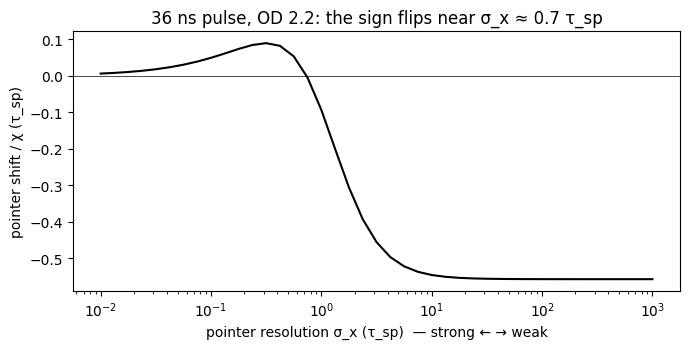

In [7]:
ch = chains[5]
st = 36 / 26
sxs = np.logspace(-2, 3, 41)
curve = [pointer_shift(ch, st, sx) for sx in sxs]
for sx in (1000, 10, 3, 1, 0.3, 0.1, 0.01):
    print(f"σ_x = {sx:7.2f} τ_sp:  pointer shift / χ = {pointer_shift(ch, st, sx):+.3f}")
print(f"check against the closed discrete model at σ_x = 1: {pointer_shift_discrete(ch, st, 1.0, npts=15):+.3f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogx(sxs, curve, 'k'); ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('pointer resolution σ_x (τ_sp)  — strong ← → weak'); ax.set_ylabel('pointer shift / χ (τ_sp)')
ax.set_title('36 ns pulse, OD 2.2: the sign flips near σ_x ≈ 0.7 τ_sp')
plt.tight_layout(); plt.show()

### 📖 In depth: why a strong probe silences the atoms

The pointer couples to "atom excited" through its momentum. A pointer that resolves time sharply has a wide spread of momenta, and each momentum shifts the atomic levels by a different
fixed amount. Averaged over that spread, the atoms sit mostly far off resonance, where they barely touch the photon and its group delay is small and positive. The positive bump in between is that
off-resonance group delay mixed in by the pointer's momentum spread.

This is different from notebook 11's Zeno effect. There, repeated records of the configuration freeze it. Here nothing is recorded at intermediate times: the pointer records only the total, and
the atoms stop responding because they have been detuned.

The crossover needs a resolution of about one atomic lifetime per photon. The real experiment's probe is three to four orders of magnitude weaker than that. Its noise is about $10^4$ times the signal,
but only the quantum part of that noise, roughly a quarter of it, disturbs the atoms.

<!-- expansion:17:recap-5 -->
### 📝 Recap: section 5

- Weak probe: the weak value, negative for this 36 ns pulse ($-0.558$ on the continuum line).
- Resolution below about $0.7\,\tau_\text{sp}$: the sign flips, because the pointer's momentum spread mixes in the positive off-resonance group delay.
- Sharp probe: the shift goes to zero, because the atoms are detuned and stop responding. This is not the Zeno effect: nothing is recorded at intermediate times.
- The real experiment's probe is three to four orders of magnitude weaker than the crossover, so it measures the weak value.


## 6. A Second Case: Negative Time Behind a Barrier

Here the configurations are positions on a chain, which is ISP's home ground. A wavepacket hits a low barrier; ask how long it spends in the 10 sites *behind* the barrier, given that it is finally
reflected. The answers for transmitted and reflected particles, weighted by their probabilities, must add up to the unconditioned time (a sum rule the quasiprobability satisfies exactly).

This effect is not new. Steinberg found it in 1995 (PRL 74, 2405, quant-ph/9501015): the reflected particle's conditional time density beyond the barrier is nonzero and oscillates in
sign, $d\tau_R(x) \propto \sin(2kx + \arg t)\,dx$, and averages to zero over a long region. Our 10 sites span two to three periods of that oscillation (period $\pi/k$, about 3 sites at $k_0 = 1$ and 5 at $k_0 = 0.6$); what is left over is small and negative.
What this notebook adds is only the split into a recorded part and half the defect.

The last printed column, the defects summed over both outcomes, would be zero if "transmitted" and "reflected" covered every ending. They don't quite: cutting the wave function down to the
region at $t$ also loads states bound to the barrier, and that weight ends in neither outcome, so the sum is small and positive.

<!-- expansion:17:derive-sum-rule -->
### 🧮 Worked derivation: the sum rule, and why some outcome must pay

Sum the quasiprobability over all final outcomes. Since $\sum_f \Pi_f = 1$,

$$\sum_f q(\text{in}, f; t) = \mathrm{Re}\,\langle\psi_t|\Pi_\text{in}|\psi_t\rangle = P(\text{in at } t).$$

Integrate over $t$: $\sum_f P(f)\,\tau_f = \int P(\text{in at } t)\,dt$, the ordinary unconditioned dwell time. The conditional times are a split of a genuine, positive total.

The defects also sum to zero, *if the outcomes cover everything*: $\sum_f \Delta_f = 1 - \sum_{b, f} P_\text{seq}(b, f) = 1 - 1 = 0$. Here they don't quite. The outcomes are "left" and "right", and the
recorded process can also end "still in the barrier", because cutting the wave function loads states bound to the barrier. So the printed defect sums are small and positive (0.001 to 0.012); adding
"still in the barrier" as a third outcome restores zero. The unrecorded process has left the barrier by the end, so the quasiprobability sum rule above is exact.

Approximately, then, whenever the defect lowers one outcome's time it raises another's. In the next cell the reflected particle takes the negative share and the transmitted one the positive.


In [8]:
print("time spent in the 10 sites behind the barrier, by final outcome (units 1/hopping)")
for V0, w_bar, k0 in [(0.6, 4, 1.0), (0.8, 2, 0.6), (1.2, 4, 1.0)]:
    tc = TunnelChain(V0=V0, w_bar=w_bar)
    r = tc.run('behind', k0=k0)
    t, f = r['transmitted'], r['reflected']
    print(f"  V = {V0}, width {w_bar}, k0 = {k0}: P_R = {f['P_f']:.3f}, τ_R = {f['tau']:+.3f} [τ_seq {f['tau_seq']:+.3f}, τ_defect {f['tau_defect']:+.3f}];"
          f"  τ_T = {t['tau']:+.2f};  sum rule {t['P_f']*t['tau'] + f['P_f']*f['tau']:.4f} = {f['dwell']:.4f};"
          f"  defects summed over both outcomes {t['P_f']*t['tau_defect'] + f['P_f']*f['tau_defect']:+.4f}")

time spent in the 10 sites behind the barrier, by final outcome (units 1/hopping)


  V = 0.6, width 4, k0 = 1.0: P_R = 0.207, τ_R = -0.033 [τ_seq +0.444, τ_defect -0.477];  τ_T = +5.94;  sum rule 4.7014 = 4.7014;  defects summed over both outcomes +0.0123


  V = 0.8, width 2, k0 = 0.6: P_R = 0.750, τ_R = -0.105 [τ_seq +0.060, τ_defect -0.165];  τ_T = +9.15;  sum rule 2.2042 = 2.2042;  defects summed over both outcomes +0.0073


  V = 1.2, width 4, k0 = 1.0: P_R = 0.962, τ_R = -0.014 [τ_seq +0.002, τ_defect -0.016];  τ_T = +6.26;  sum rule 0.2217 = 0.2217;  defects summed over both outcomes +0.0011


<!-- expansion:17:recap-6 -->
### 📝 Recap: section 6

- The same split works in the position basis, ISP's home ground: no photons, no atoms, only sites on a chain.
- A particle that is finally reflected reports a negative time in the region just behind the barrier, a region it never needs to visit. Steinberg found this in 1995: the time density there oscillates in sign with position.
- The sum rule over outcomes is exact: the negative time is a redistribution between outcomes, not a loss.


### 🔭 Looking ahead

**Connections.**
- Notebook 05: the defect as the interference fringe; here it is the negative part of a dwell time.
- Notebook 06: records and division events. Notebook 11: dense records and the Zeno effect. Section 5's strong probe looks similar but is a different mechanism (detuning, not records); a probe
  that records "excited or not" at each moment would be the real analogue and is a possible extension.
- Notebook 10: the level+band model this one extends, and its defect Δ for "decayed or not".

**Possible extensions.** A three-dimensional cloud with Doppler broadening; multilevel atoms; the imaginary part of the weak value (which kicks the pointer's momentum); post-selected fluorescence of
a superconducting qubit (Campagne-Ibarcq et al., arXiv:1311.5605) as a third test.

**Prior work (checked 2026-11-09).**
- The identity: Halliwell, arXiv:1508.02271 (PRA 93, 022123 (2016)), eqs. (2.1), (2.4)–(2.5), in a Leggett–Garg setting; Goldstein and Page's linear positivity; the decoherence functional of
  consistent histories. Its eq. (2.4) prints $2\,\mathrm{Re}\,D$, a factor its own definition (2.5) does not support (checked in the last arXiv version, v5; the typeset journal page was not read).
  Halliwell et al., PRA 99, 012124 (2019), eq. (2.3), give the corrected form $q = p + \mathrm{Re}\,D$.
- The Kirkwood–Dirac review (Arvidsson-Shukur et al., arXiv:2403.18899) does not discuss dwell or tunnelling times; it cites Steinberg, PRA 52, 32 (1995), the origin of weak-value dwell times.
- The experiment: Angulo et al., arXiv:2409.03680; Sinclair et al., PRX Quantum 3, 010314 (2022). The theory: Thompson et al., arXiv:2310.00432, who explain negative values as interference
  (a Fabry–Perot picture, their App. H) without this split.
- Weak-to-strong crossovers of weak values are studied in general (Dressel et al., Rev. Mod. Phys. 86, 307 (2014)).
- The negative time behind the barrier: Steinberg, PRL 74, 2405 (1995) (quant-ph/9501015), and PRA 52, 32 (1995), with the sum rule and a back-action explanation.
- Anomalous weak values as witnesses of disturbance and of Leggett–Garg violation: Williams & Jordan, PRL 100, 026804 (2008); Pusey, PRL 113, 200401 (2014) (as proofs of contextuality);
  Pan, PRA 102, 032206 (2020). Section 4's "witness" argument is of this kind.
- Not found in our searches: an ISP treatment of negative dwell times; the probe-strength curve for this experiment.
  No related work from NIST, JILA or CU Boulder was found. Literature notes: `notes/lit-negative-dwell-time-2026-11-09.md`.

<!-- expansion:17:books-barandes-measurement -->
### 📚 How this fits Barandes's account of measurement

Barandes's deflationary moves have one shape: a puzzling quantum phenomenon is what an indivisible process looks like when you ask it a question it can only answer at a
division event. Interference (notebook 05) is the defect between "recorded which slit" and "not recorded". Collapse (notebook 06) is a division event. This notebook applies the same move to
anomalous weak values: half the defect, showing through a probe gentle enough not to make a division event. The move itself is not new: anomalous weak values have been read as signs of
disturbance and Leggett–Garg violation since Williams & Jordan (2008). Two limits apply. How the number splits depends on what a division event would record. And section 5's strong probe
removes the anomaly by detuning the atoms, not by recording them, so it does not test the division-event reading. A probe that records "excited or not" at each moment would.


## Summary

- **The identity.** For a yes/no question at time $t$ and a post-selection $f$, what a weak probe reports splits exactly into a division-event part and half the indivisibility defect:
  $q = P_\text{seq} + \Delta_f/2$ (Halliwell's identity; a two-line proof, which the model's numerics reproduce to $10^{-15}$).
- **The experiment reproduced.** In a closed model of atoms in a one-way waveguide, the excitation time caused by a transmitted photon tracks the group delay of the model's own transmitted light (Thompson et al.'s prediction), and
  $\tau_T/\tau_0$ runs from $+0.41$ (10 ns, OD 4) to $-0.45$ (36 ns, OD 4) and $-0.70$ (36 ns, OD 2.2): positive for broadband pulses, negative for narrowband ones, as in the experiment's Fig. 3.
  ($\tau_0 = \int\langle\hat N_e\rangle\,dt$, the paper's definition; normalizing by the scattering probability times $\tau_\text{sp}$ instead gives $+0.45$, $-0.50$ and $-0.77$.)
  This is a one-dimensional model, not a fit.
- **What the split means.** A negative reported time witnesses indivisibility: no account with a division event of the in/out variable at every probed time can give it, whatever is recorded. In ISP the atoms are excited or not
  at every moment, but there is no joint probability across those times to report; what is recorded is the pointer and photon at the end, and the pointer's average is negative.
- **What it doesn't mean.** The division-event part is not an "honest" time: checking disturbs, and for rare outcomes it can exceed the reported time by a factor of hundreds. Nor is the split
  unique: it changes with the grain of the record and even with the atom spacing, while $\tau_T$ does not.
- **Probe strength.** The negative time belongs to weak probes only. With a pointer of resolution better than about $0.7\,\tau_\text{sp}$ the sign flips, and a sharp pointer detunes the atoms so far that the photon passes them untouched.
- **A second case.** A particle that is finally reflected "spends a negative time" in the region just behind a barrier (Steinberg's 1995 result), with the sum rule over outcomes exact.

Caveats: a one-dimensional chiral model in which each atom is optically thick (OD 0.45), so its line differs slightly from a dilute cloud's; no Doppler or inhomogeneous broadening; two-level atoms;
an idealised pointer that records the total excitation time; the 27 ns, OD 4 sign depends on the finite loss bands; the model integrates over the whole run, while the experiment integrates
inside a window cut where the tails reach 30% of the peak; and in this model the paper's two expressions for $\tau_0$ differ by a factor 0.9 (section 1).

Prior work: the identity is Halliwell (arXiv:1508.02271), with Goldstein–Page linear positivity behind it; weak-value dwell times, and the negative time behind a barrier, are Steinberg (PRA 52, 32 and
PRL 74, 2405 (1995)); the experiment and its theory are Angulo et al. (arXiv:2409.03680) and Thompson et al. (arXiv:2310.00432); anomalous weak values as signs of disturbance and Leggett–Garg
violation are Williams & Jordan (2008) and Pusey (2014). Not found in our searches: an ISP reading of negative dwell times.

### 📖 In depth: the one-paragraph version

A weak probe of "is the atom excited?", read only on runs where the photon got through, reports a quasiprobability that is exactly the probability you would get by recording the answer, plus half of
the amount by which recording would change the outcome. The second piece is Barandes's indivisibility defect. In a closed model of the 2024 experiment the reported time equals the group
delay (a consequence of the derivative relation of section 3, not of the split) and is negative for narrowband pulses, as measured. Since the recorded piece is never negative, a negative report is a witness that the process did not divide at all of those times; an ISP, which has
joint probabilities only at division events, has no non-negative "time spent" to offer instead. How the number divides between the two pieces depends on what is recorded; that it can be
negative does not. Stronger probes push the number positive and then to zero. The same thing happens to a particle reflected from a barrier, which "spends negative time" just behind it, as
Steinberg found in 1995.

<!-- expansion:17:check -->
### 📝 Check your understanding

1. *Why can't the probe's report be read as a probability of being excited, given transmission?*
   An ISP has joint probabilities across times only at division events. Without one at $t$ there is no such probability; the report is $P_\text{seq} + \Delta_f/2$, and the second term can be negative.
2. *What would a negative report rule out?*
   Any account in which the excited-or-not variable divides at every probed time, Markov or not, since then the report would be $P_\text{seq} \ge 0$.
3. *Why is $\tau_\text{seq}$ not the "true" time?*
   It is the answer of a different experiment, one that records the variable. Recording disturbs; for a tunnelling particle it multiplies the time by hundreds.
4. *Where does Γ fall short here?*
   The size of $\tau_T$ is a phase derivative (the group delay), invisible to $|U|^2$ in the frequency basis. Γ explains why no positive answer exists, not the number that comes out.
5. *What happens to the negative time if the probe gets stronger?*
   It turns positive below a resolution of about $0.7\,\tau_\text{sp}$, then goes to zero as the pointer's momentum spread detunes the atoms. This is not the Zeno effect.
6. *Is the split into $\tau_\text{seq}$ and $\tau_\text{defect}$ a property of the experiment?*
   No. It changes with the grain of the record and even with the atom spacing, while $\tau_T$ stays put. What is fixed is the sum, and the fact that a negative sum rules out any record.
